In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
eq = pd.read_csv("earthquakes.tsv", sep="\t")
eq.shape

(6698, 39)

In [ ]:
cleaneq = eq.dropna(subset=['Mag', 'Focal Depth (km)'])
cleaneq.shape

(3566, 39)

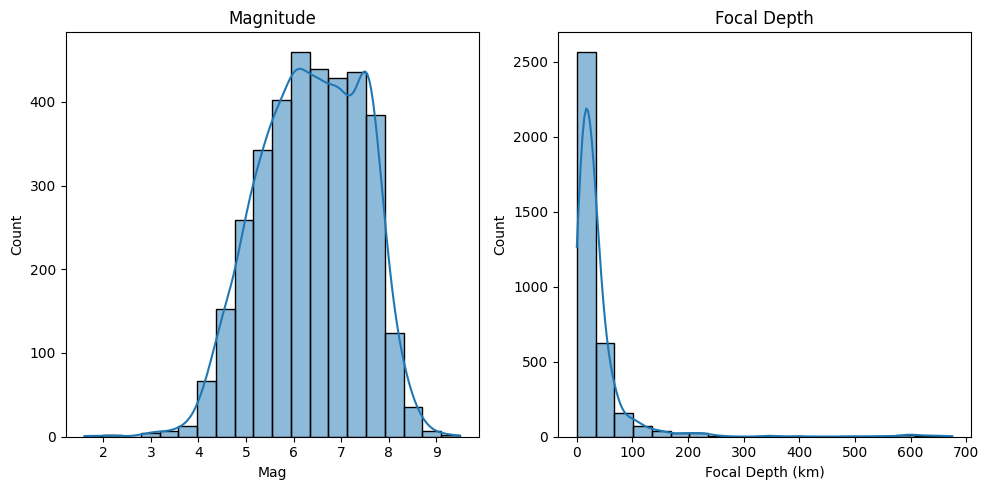

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(10,5))

sns.histplot(x="Mag",data=cleaneq,bins=20,kde=True,ax=axes[0])
axes[0].set_title("Magnitude")
sns.histplot(x="Focal Depth (km)",data=cleaneq,bins=20,kde=True,ax=axes[1])
axes[1].set_title("Focal Depth")

plt.tight_layout()
plt.show()

This kdeplot helps showcase the connection between magnitude and focal depth in significant earthquakes

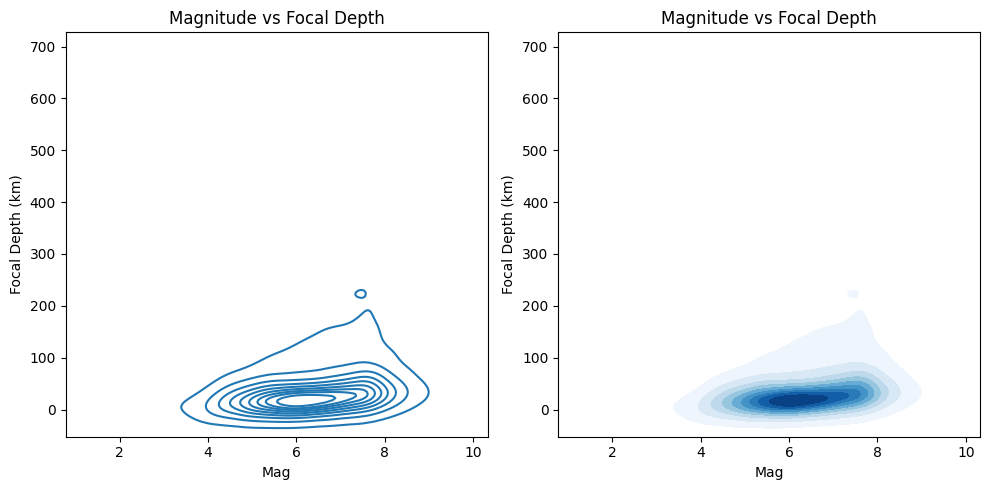

In [ ]:
fig, axes= plt.subplots(1,2,figsize=(10,5))

sns.kdeplot(data=cleaneq,x="Mag",y="Focal Depth (km)",ax=axes[0])
axes[0].set_title("Magnitude vs Focal Depth")
sns.kdeplot(data=cleaneq,x="Mag",y="Focal Depth (km)",fill=True,cmap="Blues",ax=axes[1])
axes[1].set_title("Magnitude vs Focal Depth")

plt.tight_layout()
plt.show()

In [ ]:
cleanyeareq = cleaneq.dropna(subset=['Year'])
cleanyeareq.shape

(3566, 39)

This countplot helps showcase the increase in the documentation in significant earthquakes across history

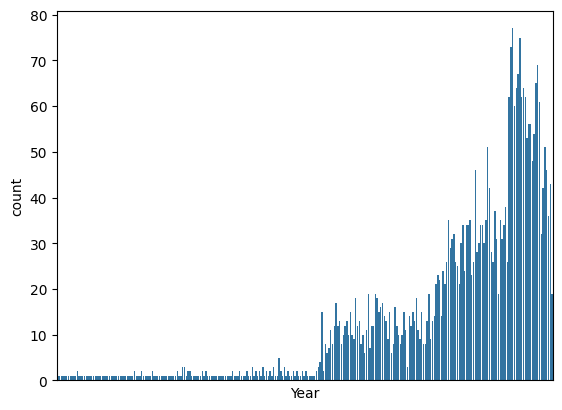

In [ ]:
ax = sns.countplot(x="Year",data=cleanyeareq)
ax.tick_params(axis='x',bottom=False,labelbottom=False)
plt.show()

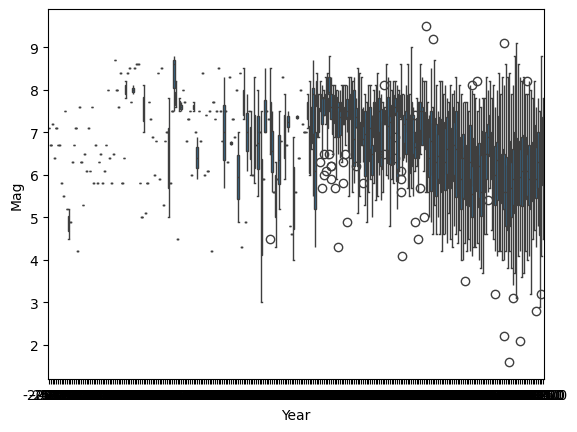

In [ ]:
sns.boxplot(x="Year",y="Mag",data=cleanyeareq)
plt.show()

In [ ]:
cleanvioeq = eq.dropna(subset=['MMI Int','Mag'])
cleanvioeq.shape

(2541, 39)

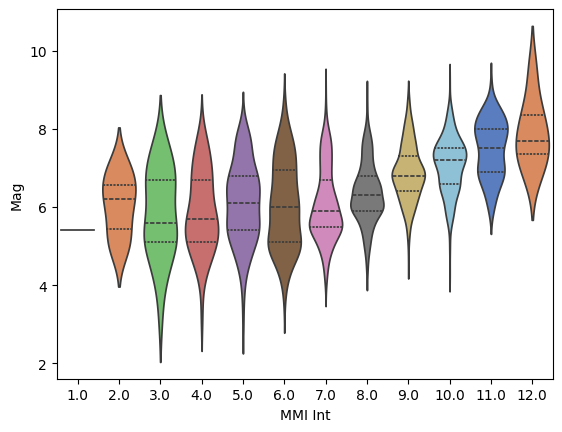

In [ ]:
sns.violinplot(x="MMI Int",y="Mag",data=cleanvioeq,inner="quartile",palette="muted",hue="MMI Int",legend=False)
plt.show()

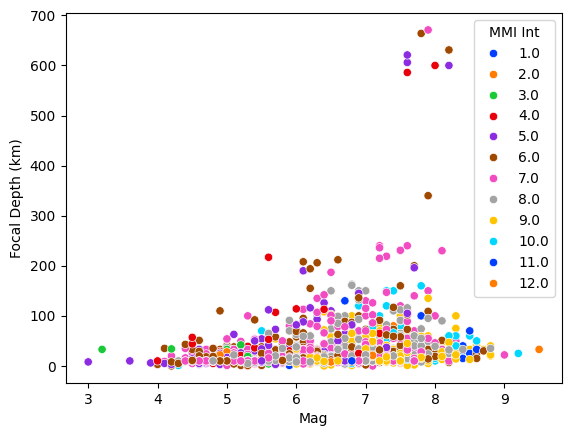

In [ ]:
sns.scatterplot(x="Mag", y="Focal Depth (km)", hue="MMI Int", data=cleaneq,palette = "bright")
plt.show()

In [ ]:
cleanco = eq.copy()
cleanco["Country"] = (eq["Location Name"].str.split(":").str[0].str.strip())
cleanco.shape

top5 = cleanco["Country"].value_counts().head(5).index
top5

Index(['CHINA', 'INDONESIA', 'IRAN', 'JAPAN', 'TURKEY'], dtype='object', name='Country')

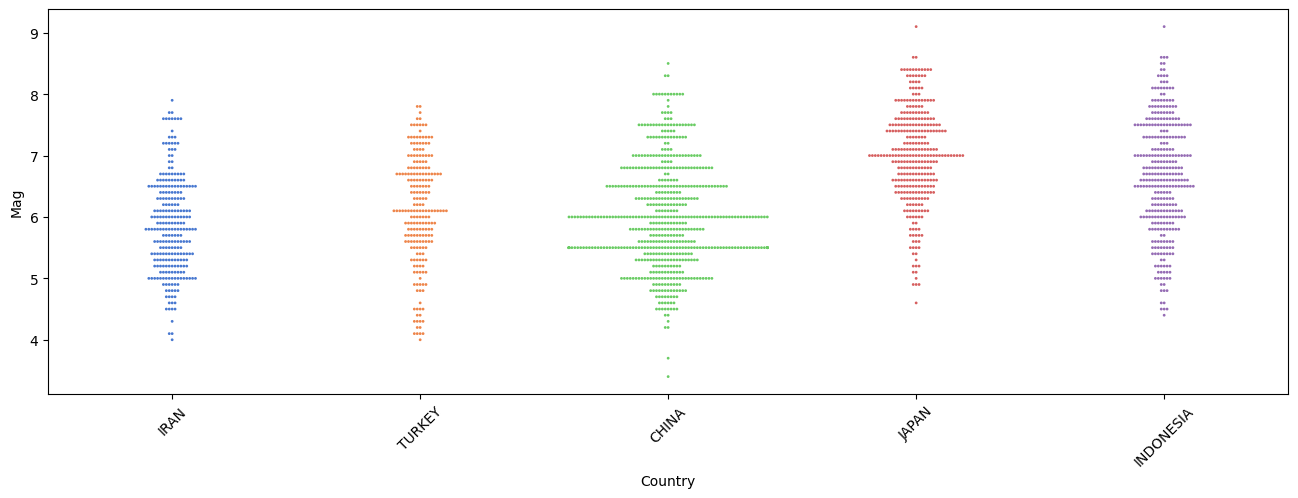

In [ ]:
plt.figure(figsize=(16,5))

sns.swarmplot(x="Country",y="Mag",data=cleanco[cleanco["Country"].isin(top5)],size=2,hue = "Country", palette = "muted")
plt.xticks(rotation=45)
plt.show()

In [ ]:

cleanyeareq["Century"]= (eq["Year"] // 100 * 100)
cleanyeareq.shape

(3566, 40)

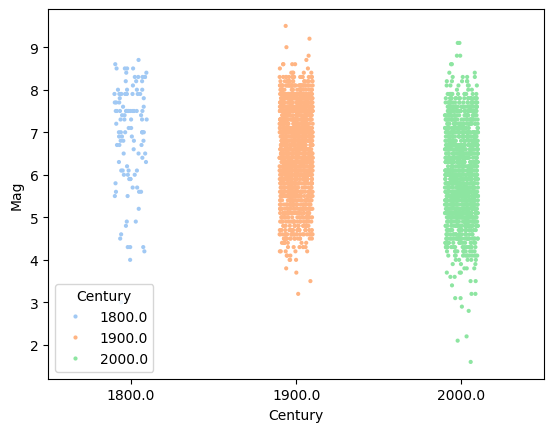

In [ ]:

sns.stripplot(x="Century",y="Mag",data=cleanyeareq[cleanyeareq["Year"] >= 1800],jitter=True,size=3,hue = "Century",palette = "pastel")
plt.show()